# Часть 1

## Этап 1

In [1]:
# Загрузка и первичная проверка данных
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier, CatBoostRegressor
from sklift.metrics import uplift_auc_score, qini_auc_score, uplift_at_k

DATA_PATH = "uplift_fp_data.csv"
df = pd.read_csv(DATA_PATH)
print(f"Размер данных: {df.shape[0]:,} строк × {df.shape[1]} столбцов")
display(df.head())
print("\nТипы данных:")
display(df.dtypes.rename("dtype").to_frame())
print("\nПропуски:")
display(df.isna().sum().rename("число пропусков").to_frame())
print(f"Полных дубликатов: {df.duplicated().sum():,}")
print("\nСводные статистики:")
display(df.describe().T)
assert set(df.columns) == {"recency", "history_segment", "history", "mens", "womens", "zip_code", "newbie", "channel", "treatment", "target"}
assert df[["treatment", "target"]].isin([0, 1]).all().all()


Размер данных: 64,000 строк × 10 столбцов


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,treatment,target
0,10,1,142.44,1,0,1,0,1,1,0
1,6,2,329.08,1,1,2,1,2,0,0
2,7,1,180.65,0,1,1,1,2,1,0
3,9,4,675.83,1,0,2,1,2,0,0
4,2,0,45.34,1,0,0,0,2,1,0



Типы данных:


,dtype
recency,int64
history_segment,int64
history,float64
mens,int64
womens,int64
zip_code,int64
newbie,int64
channel,int64
treatment,int64
target,int64



Пропуски:


,число пропусков
recency,0
history_segment,0
history,0
mens,0
womens,0
zip_code,0
newbie,0
channel,0
treatment,0
target,0


Полных дубликатов: 7,015

Сводные статистики:


,count,mean,std,min,25%,50%,75%,max
recency,64000.0,5.763734,3.507592,1.00,2.00,6.00,9.0000,12.00
history_segment,64000.0,1.481969,1.544514,0.00,0.00,1.00,2.0000,6.00
history,64000.0,242.085656,256.158608,29.99,64.66,158.11,325.6575,3345.93
mens,64000.0,0.551031,0.497393,0.00,0.00,1.00,1.0000,1.00
womens,64000.0,0.549719,0.497526,0.00,0.00,1.00,1.0000,1.00
zip_code,64000.0,0.748469,0.697936,0.00,0.00,1.00,1.0000,2.00
newbie,64000.0,0.502250,0.499999,0.00,0.00,1.00,1.0000,1.00
channel,64000.0,1.319609,0.678254,0.00,1.00,1.00,2.0000,2.00
treatment,64000.0,0.334172,0.471704,0.00,0.00,0.00,1.0000,1.00
target,64000.0,0.146781,0.353890,0.00,0.00,0.00,0.0000,1.00


## Этап 2

### EDA


Распределение treatment:


,число наблюдений
treatment,
Контроль,42613
Воздействие,21387


,наблюдения,положительные,доля
treatment,,,
Контроль,42613,6156,0.144463
Воздействие,21387,3238,0.151400


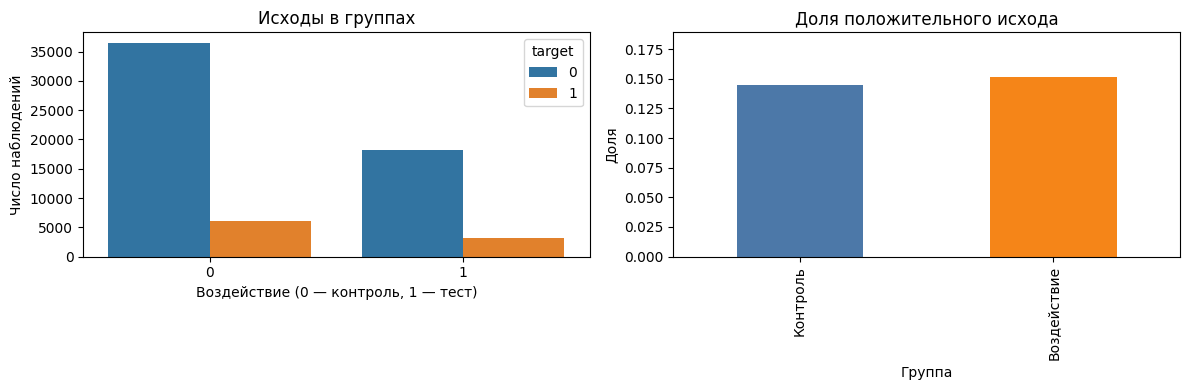

In [2]:
# Распределение воздействия, исхода и сравнение групп
print("Распределение treatment:")
display(df["treatment"].value_counts().sort_index().rename(index={0:"Контроль",1:"Воздействие"}).to_frame("число наблюдений"))
summary = df.groupby("treatment")["target"].agg(наблюдения="size", положительные="sum", доля="mean").rename(index={0:"Контроль",1:"Воздействие"})
display(summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="treatment", hue="target", ax=axes[0])
axes[0].set(title="Исходы в группах", xlabel="Воздействие (0 — контроль, 1 — тест)", ylabel="Число наблюдений")
summary["доля"].plot(kind="bar", ax=axes[1], color=["#4C78A8", "#F58518"])
axes[1].set(title="Доля положительного исхода", xlabel="Группа", ylabel="Доля", ylim=(0, max(summary["доля"])*1.25))
plt.tight_layout()


В выборке 64 000 наблюдений, пропусков нет. Полных совпадений строк 7 015; без идентификатора клиента их нельзя уверенно считать повторными записями, поэтому они сохранены. Доли положительного `target`: 14,45% при `treatment=0` и 15,14% при `treatment=1`. Совпадение размеров групп и числа положительных откликов с распределениями Hillstrom указывает, что учебный `treatment=0` может объединять No E-Mail и Mens E-Mail, а `treatment=1` — Womens E-Mail. Это соответствие вероятно, но происхождение каждого столбца данными окончательно не подтверждено. `target` трактуем только как наблюдаемый бинарный отклик: нельзя утверждать, что это использование промокода или покупка.

# Этап 2

### Проверка на статистическую значимость

Для сравнения долей бинарного отклика в двух независимых группах применён двусторонний z-тест для пропорций. Большие размеры групп позволяют использовать нормальную аппроксимацию; проверяется равенство долей при уровне значимости 5%. Тест выявляет статистическое различие наблюдаемых долей, но сам по себе не доказывает причинный эффект. Кроме того, если контрольная группа объединяет No E-Mail и Mens E-Mail, результат не является сравнением рассылки с отсутствием рассылки.

In [3]:
# Сравнение долей положительного исхода между независимыми группами
from statsmodels.stats.proportion import proportions_ztest
counts = df.groupby("treatment")["target"].agg(["sum", "count"]).sort_index()
stat_z, p_value = proportions_ztest(counts["sum"].to_numpy(), counts["count"].to_numpy())
rate_control = counts.loc[0,"sum"] / counts.loc[0,"count"]
rate_treat = counts.loc[1,"sum"] / counts.loc[1,"count"]
print(f"Контроль: {rate_control:.4%}; тест: {rate_treat:.4%}")
print(f"Разность долей (тест − контроль): {rate_treat-rate_control:.4%}")
print(f"z={stat_z:.3f}, p-value={p_value:.4g}")


Контроль: 14.4463%; тест: 15.1400%
Разность долей (тест − контроль): 0.6937%
z=-2.339, p-value=0.01932


## Построение корреляций

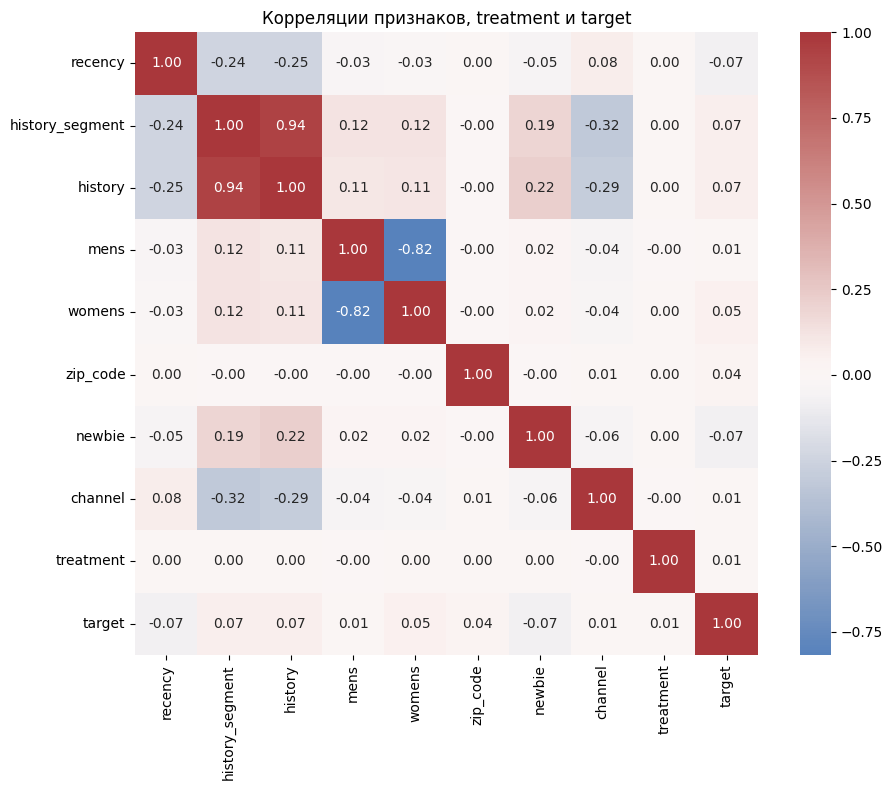

In [4]:
# Корреляционная матрица числовых признаков и целевых столбцов
corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Корреляции признаков, treatment и target")
plt.tight_layout()


Корреляционная матрица показывает линейные связи числовых кодов признаков, `treatment` и `target`, но не причинность и не нелинейные зависимости. Если `treatment=0` объединяет две исходные группы Hillstrom, корреляция с `target` отражает различие относительно этой смеси. Коды `history_segment`, `zip_code` и `channel` имеют категориальный смысл, поэтому коэффициенты Пирсона для них следует трактовать ограниченно.

## Этап 3

Для сравнения выбраны S-, T- и X-Learner на CatBoost. S-Learner моделирует отклик с признаком воздействия, T-Learner обучает отдельные модели по группам, X-Learner дополнительно моделирует псевдоэффекты. Оценки описывают различие ожидаемого бинарного отклика при `treatment=1` и относительно объединённой группы `treatment=0`. При вероятном соответствии Hillstrom это Womens E-Mail против смеси No E-Mail и Mens E-Mail, а не чистый эффект рассылки против отсутствия рассылки. Причинная интерпретация требует подтверждения рандомизации и точного определения столбцов.

### Советы по обучению и инференсу моделей
1. Некоторые uplift модели из библиотеки `causalml` будут требовать категориальные значения воздействия. Для этого используйте маппинг
#### Пример использования маппинга
```python
treatment_mapping = {
    0: 'control',
    1: 'treatment'
}
treatment_train_mapped = treatment_train.map(treatment_mapping)
treatment_test_mapped = treatment_test.map(treatment_mapping)
```

2. При вызове метода `.predict` и получения метрик для тестовой выборки не забывайте применять к прогнозам метод `squeeze()`, чтобы преобразовать многомерный массив в одномерный, что поможет получить адекватные метрики.

3. Для воспроизводимости результатов и объективной оценки не забывайте применять `random_state=42` для моделей, а также при разделении выборки

### Разбиение выборки на тренировочную и тестовую

In [5]:
# Разделение 80/20 со стратификацией по комбинации treatment и target
feature_cols = [c for c in df.columns if c not in ("treatment", "target")]
X = df[feature_cols].copy()
treatment = df["treatment"].astype(int)
y = df["target"].astype(int)
strata = treatment.astype(str) + "_" + y.astype(str)
X_train, X_test, t_train, t_test, y_train, y_test = train_test_split(
    X, treatment, y, test_size=0.2, random_state=42, stratify=strata
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train treatment/target strata:")
display(pd.crosstab(t_train, y_train, normalize="all").round(4))

assert len(X_train) == 51200 and len(X_test) == 12800
assert set(X.columns).isdisjoint({"treatment", "target"})


Train: (51200, 8) Test: (12800, 8)
Train treatment/target strata:


target,0,1
treatment,,
0,0.5696,0.0962
1,0.2836,0.0506


### Обучение выбранного бейзлайна

In [6]:
# Единые параметры CatBoost для сопоставимого сравнения
CAT_PARAMS = dict(iterations=350, depth=6, learning_rate=0.05, l2_leaf_reg=5,
                  loss_function="Logloss", random_seed=42, verbose=False,
                  allow_writing_files=False, thread_count=4, auto_class_weights="Balanced")

def new_classifier():
    return CatBoostClassifier(**CAT_PARAMS)

# S-Learner: одна модель включает индикатор воздействия; прогнозируем оба потенциальных исхода.
s_model = new_classifier()
s_model.fit(X_train.assign(treatment=t_train.to_numpy()), y_train)
s_uplift = (s_model.predict_proba(X_test.assign(treatment=1))[:, 1]
            - s_model.predict_proba(X_test.assign(treatment=0))[:, 1])


### Расчет метрик для выбранного бейзлайна на тестовой выборке

In [7]:
# Оценка на отложенной тестовой выборке
def uplift_metrics(y_true, uplift, treatment_true):
    return {
        "Uplift AUC": uplift_auc_score(y_true, uplift, treatment_true),
        "Qini AUC": qini_auc_score(y_true, uplift, treatment_true),
        "Uplift@30%": uplift_at_k(y_true, uplift, treatment_true, strategy="overall", k=0.3),
    }
results = {"S-Learner": uplift_metrics(y_test, s_uplift, t_test)}
# Uplift@30%: верхние 30% тестовой выборки по прогнозу, затем разность долей отклика.
segment_size = int(len(y_test) * 0.30)
top_idx = np.argsort(np.asarray(s_uplift), kind="mergesort")[::-1][:segment_size]
top_t = np.asarray(t_test)[top_idx]
top_y = np.asarray(y_test)[top_idx]
print(f"Размер top-сегмента: {segment_size:,} из {len(y_test):,}")
print(f"Контроль в сегменте: {(top_t == 0).sum():,}; тест: {(top_t == 1).sum():,}")
print(f"Ручная проверка uplift@30%: {top_y[top_t == 1].mean() - top_y[top_t == 0].mean():.6f}")
print(results["S-Learner"])


Размер top-сегмента: 3,840 из 12,800
Контроль в сегменте: 2,534; тест: 1,306
Ручная проверка uplift@30%: 0.036652
{'Uplift AUC': 0.02249327623966757, 'Qini AUC': 0.05038227507670589, 'Uplift@30%': 0.036651916780181565}


# Обучение 2 моделей 

### Обучение модели 1

In [8]:
# T-Learner: отдельный классификатор исхода для каждой группы
control_model = new_classifier().fit(X_train.loc[t_train == 0], y_train.loc[t_train == 0])
treatment_model = new_classifier().fit(X_train.loc[t_train == 1], y_train.loc[t_train == 1])
t_uplift = (treatment_model.predict_proba(X_test)[:, 1]
            - control_model.predict_proba(X_test)[:, 1])


### Получение метрик по модели 1

In [9]:
results["T-Learner"] = uplift_metrics(y_test, t_uplift, t_test)
print(results["T-Learner"])


{'Uplift AUC': 0.017762671409707942, 'Qini AUC': 0.039542589938533275, 'Uplift@30%': 0.03591860139487124}


### Обучение модели 2

In [10]:
# X-Learner: модели исхода, псевдоэффекты в обеих группах и модели эффектов
# Используем вероятности положительного исхода как условные ожидания бинарного target.
mu0 = new_classifier().fit(X_train.loc[t_train == 0], y_train.loc[t_train == 0])
mu1 = new_classifier().fit(X_train.loc[t_train == 1], y_train.loc[t_train == 1])
X0, X1 = X_train.loc[t_train == 0], X_train.loc[t_train == 1]
y0, y1 = y_train.loc[t_train == 0], y_train.loc[t_train == 1]
# D0 = mu1(X0) - Y0; D1 = Y1 - mu0(X1)
d0 = mu1.predict_proba(X0)[:, 1] - y0.to_numpy()
d1 = y1.to_numpy() - mu0.predict_proba(X1)[:, 1]
effect0 = CatBoostRegressor(iterations=350, depth=6, learning_rate=0.05, l2_leaf_reg=5,
    loss_function="RMSE", random_seed=42, verbose=False, allow_writing_files=False, thread_count=4).fit(X0, d0)
effect1 = CatBoostRegressor(iterations=350, depth=6, learning_rate=0.05, l2_leaf_reg=5,
    loss_function="RMSE", random_seed=42, verbose=False, allow_writing_files=False, thread_count=4).fit(X1, d1)
# При случайном назначении используем равные веса групп.
x_uplift = 0.5 * (effect0.predict(X_test) + effect1.predict(X_test))


### Получение метрик по модели 2

,Uplift AUC,Qini AUC,Uplift@30%
Модель,,,
S-Learner,0.022493,0.050382,0.036652
X-Learner,0.020918,0.046662,0.034681
T-Learner,0.017763,0.039543,0.035919


,Контрольная модель эффекта,Тестовая модель эффекта,Средняя важность
recency,18.986362,21.123446,20.054904
history,18.648878,19.677687,19.163283
newbie,9.257188,15.778983,12.518085
womens,21.553793,3.344457,12.449125
channel,10.901257,11.295218,11.098238
zip_code,10.158118,11.761949,10.960033
mens,4.596168,11.034301,7.815235
history_segment,5.898236,5.983959,5.941097


Топ признаков по средней важности: recency, history, newbie, womens, channel
Важность S-Learner относится к прогнозу отклика; она не показывает причинное влияние признака на эффект воздействия.


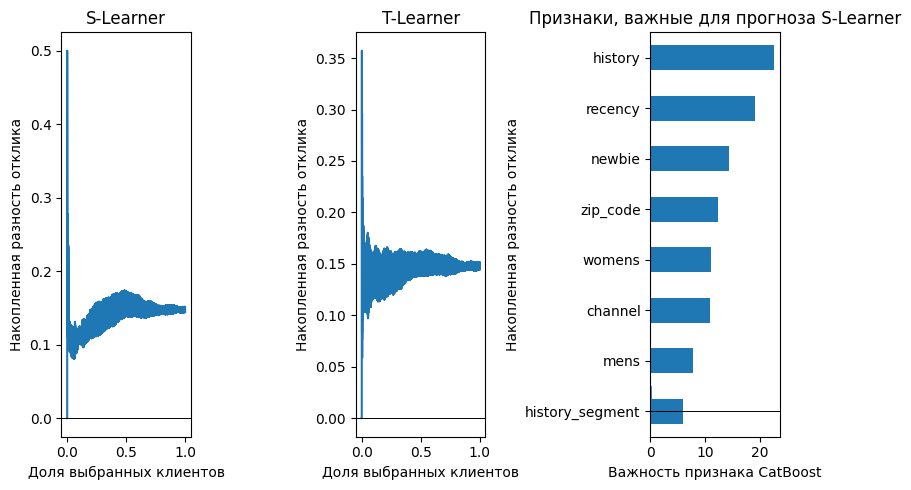

In [11]:
results["X-Learner"] = uplift_metrics(y_test, x_uplift, t_test)
results_df = pd.DataFrame(results).T
results_df.index.name = "Модель"
display(results_df.sort_values("Uplift AUC", ascending=False))

# Кривые показывают накопленный отклик при выборе клиентов по прогнозному uplift.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, {"S-Learner": s_uplift, "T-Learner": t_uplift, "X-Learner": x_uplift}.items()):
    order = np.argsort(np.asarray(pred), kind="mergesort")[::-1]
    ordered_t = np.asarray(t_test)[order]
    ordered_y = np.asarray(y_test)[order]
    cum_ctrl = np.cumsum((ordered_t == 0) * ordered_y) / np.maximum(1, np.cumsum(ordered_t == 0))
    cum_treat = np.cumsum((ordered_t == 1) * ordered_y) / np.maximum(1, np.cumsum(ordered_t == 1))
    curve = np.where(ordered_t == 1, cum_treat, cum_ctrl)
    ax.plot(np.arange(1, len(order) + 1) / len(order), curve)
    ax.axhline(0, color="black", linewidth=0.7)
    ax.set_title(name)
    ax.set_xlabel("Доля выбранных клиентов")
    ax.set_ylabel("Накопленная разность отклика")
plt.tight_layout()

# Важность признаков X-Learner берётся из моделей псевдоэффекта.
importance = pd.DataFrame({"Контрольная модель эффекта": effect0.feature_importances_,
                           "Тестовая модель эффекта": effect1.feature_importances_}, index=feature_cols)
importance["Средняя важность"] = importance.mean(axis=1)
importance = importance.sort_values("Средняя важность", ascending=False)
display(importance.head(10))
importance["Средняя важность"].head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.xlabel("Важность признака CatBoost")
plt.title("Признаки, используемые X-Learner для оценки эффекта")
plt.tight_layout()
print("Топ признаков по средней важности:", ", ".join(importance.head(5).index))


# Важность S-Learner для прогноза отклика
s_importance = pd.Series(s_model.feature_importances_, index=feature_cols + ["treatment"]).drop("treatment").sort_values(ascending=False)
s_importance.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.xlabel("Важность признака CatBoost")
plt.title("Признаки, важные для прогноза S-Learner")
plt.tight_layout()
print("Важность S-Learner относится к прогнозу отклика; она не показывает причинное влияние признака на эффект воздействия.")


На тестовой выборке лучший Uplift@30% у S-Learner (0,0367), затем T-Learner (0,0359) и X-Learner (0,0347). Это небольшое различие не проверялось отдельным тестом и не означает, что модели статистически различаются. Сравнение относится к наблюдаемому отклику в `treatment=1` относительно объединённой группы `treatment=0`; если вероятная кодировка Hillstrom верна, это Womens E-Mail против смеси No E-Mail и Mens E-Mail. Вывод нельзя переносить на решение «отправлять письмо или нет». Целевой признак не подтверждён как покупка или использование промокода, а причинная трактовка требует подтверждения исходных групп и схемы назначения воздействия.

# Часть 2

## Этап 1
Улучшите бейзлайн выбранной модели

#### Генерация признаков (опционально)

### Подбор гиперпараметров

In [ ]:
from optuna import create_study
from sklift.metrics import uplift_at_k

def objective(trial):
    # Дополните код для подбора гиперпараметров

    uplift_at_30 = uplift_at_k(y_test, uplift_pred, treatment_test, k=0.3, strategy='overall')
    return uplift_at_30

# Создаем и запускаем исследование
study = create_study(direction='maximize')
study.optimize(objective, n_trials=100)

# Выводим лучшие гиперпараметры
print("Best hyperparameters: ", study.best_params)
print("Best score: ", study.best_value)


## Этап 2

### Визуализация результатов

In [ ]:
from utils import custom_uplift_by_percentile

В данной ячейке сделайте вывод о качестве работы модели и проинтерпретируйте график `uplift by percentile` 

# Этап 3

In [ ]:
# Класс для инференса модели
class UpliftModelInference:
    """
    Класс для инференса uplift модели.
    """
    
    def __init__(self, model, feature_names, logger=None):
        """
        Инициализация класса.
        
        Аргументы:
            model: Обученная модель uplift
            feature_names: Список признаков для предсказания 
            logger: Объект для логирования (по умолчанию None)
        """
        self.model = model
        self.feature_names = ['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel']
        self.logger = logger
        
        if self.logger:
            self.logger.info("Модель UpliftModel инициализирована с признаками: %s", feature_names)

    def _transform_data(self, X):
        """
        Преобразование данных для модели.
        
        Аргументы:
            X: pandas.DataFrame с признаками
        """
        if self.logger:
            self.logger.debug("Преобразование входных данных размерности %s", X.shape)

        # реализуйте преобразование данных для модели,
        # если в финальной модели используются новые признаки
       

        return X
    
    def predict(self, X):
        """
        Получение предсказаний uplift.
        
        Аргументы:
            X: pandas.DataFrame с признаками
            
        Возвращает:
            numpy.array с предсказанными значениями uplift
        """
        # Проверяем, что датафрейм не пустой
        if X.empty:
            if self.logger:
                self.logger.error("Предоставлен пустой датафрейм")
            return None
            
        # Проверяем наличие пропущенных значений
        if X.isnull().any().any():
            if self.logger:
                self.logger.error("Входные данные содержат пропущенные значения")
            return [None]*len(X)
        
        if self.logger:
            self.logger.info("Выполняем предсказания для данных размерности %s", X.shape)

        # Проверяем наличие всех необходимых признаков
        missing_features = set(self.feature_names) - set(X.columns)
        if missing_features:
            error_msg = f"Отсутствуют признаки: {missing_features}"
            if self.logger:
                self.logger.error(error_msg)

            return [None]*len(X)
        
        # Преобразуем данные для модели
        if self.logger:
            self.logger.debug("Начинаем преобразование данных")
        X = self._transform_data(X)
        
        # Вычисляем uplift
        if self.logger:
            self.logger.debug("Выполняем предсказания модели")
        

        # Дополните код для получения предсказаний аплифта

        
        if self.logger:
            self.logger.info("Предсказания успешно завершены")
            
        return uplift


In [ ]:
model = UpliftModelInference(model= # ваш код,
                             feature_names= # ваш код)

In [ ]:
test_data = pd.DataFrame({
            'recency': [1, 2, 3],
            'history_segment': [1, 2, 3], 
            'history': [100, 200, 300],
            'mens': [1, 0, 1],
            'womens': [0, 1, 0],
            'zip_code': [1, 0, 1],
            'newbie': [0, 1, 0],
            'channel': [1, 2, 0]
        })

In [ ]:
# проверка работы класса
model.predict(test_data)